# Машинное обучение, ФКН ВШЭ

# Практическое задание 8. Обучение без учителя.

## Общая информация
Дата выдачи: 20.09.2026

Мягкий дедлайн: 04.10.2026 23:59 MSK

Жёсткий дедлайн: 11.10.2026 23:59 MSK

## Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи).

Сдавать задание после указанного срока сдачи нельзя.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке.

## Формат сдачи
Задания сдаются через систему anytask. Посылка должна содержать:
* Ноутбук homework-practice-08-Username.ipynb

Username — ваша фамилия на латинице

## О задании

В этом задании мы посмотрим на несколько алгоритмов кластеризации и применим их к географическим и текстовым данным. Также мы подробно остановимся на тематическом моделировании текстов, задаче обучения представлений и в каком-то смысле поработаем с semi-supervised learning.



In [56]:
import pandas as pd
import numpy as np

np.random.seed(0xFFFFFFF)

**Задание 0 (1e-100 балла)**. Какие ожидания от курса?

In [57]:
# ээээ Евгений Андреевич вперед

## Часть 1. Кластеризация автобусных остановок

В этом задании мы сравним разные алгоритмы кластеризации для данных об автобусных остановках Москвы.

**Задание 1.1 (1 балл).** Реализуйте алгоритм спектральной кластеризации, который упоминался на лекции. Для этого разберитесь с кодом шаблона, данного ниже, и допишите недостающую функцию. Напомним, что для графа с матрицей смежности $W = \{w_{ij}\}_{i, j = 1 \dots \ell}$ лапласиан определяется как:

$$
L = D - W,
$$

где $D = \text{diag}(d_1, ..., d_{\ell}), d_i = \sum_{j=1}^{\ell} w_{ij}$.

In [58]:
from sklearn.base import ClusterMixin
from sklearn.cluster import KMeans


class GraphClustering(ClusterMixin):
    def __init__(self, n_clusters=8, n_components=None, **kwargs):
        '''
        Spectral clustering algorithm
        param n_clusters: number of clusters to form
        param n_components: number of eigenvectors to use
        '''

        if n_components is None:
            n_components = n_clusters

        self.n_components = n_components
        self.kmeans = KMeans(n_clusters=n_clusters, **kwargs)

    def fit_predict(self, X, y=None):
        '''
        Perform spectral clustering from graph adjacency matrix
        and return vertex labels.
        param X: (n_samples, n_samples) - graph adjacency matrix
        return: (n_samples, ) - vertex labels
        '''

        eigenvectors = self._generate_eigenvectors(X)
        embedding = eigenvectors[:, 1:]
        
        norms = np.linalg.norm(embedding, axis=1, keepdims=True)
        embedding = embedding / np.maximum(norms, 1e-12)
        
        labels = self.kmeans.fit_predict(embedding)
        return labels

    def _generate_eigenvectors(self, X):
        '''
        Compute eigenvectors for spectral clustering
        param X: (n_samples, n_samples) - graph adjacency matrix
        return: (n_samples, n_components) - eigenvectors
        '''

        D = np.diag(X.sum(axis=0))
        L = D - X
        _, eigenvectors = np.linalg.eigh(L)
        
        return eigenvectors[:, : self.n_components]
        
        


Перед тем, как переходить к следующему заданию, протестируйте свое решение.

In [59]:
n_blocks, n_vertices = 10, 1000
block_vertices = n_vertices // n_blocks

X = np.zeros((n_vertices, n_vertices))
for i in range(0, n_vertices, block_vertices):
    X[i:i + block_vertices, i:i + block_vertices] = np.sqrt(i + 1)

graph_clustering = GraphClustering(n_clusters=n_blocks)
labels = graph_clustering.fit_predict(X)

true_labels = np.zeros(n_vertices, dtype=np.int32)
for i in range(0, n_vertices, block_vertices):
    true_labels[i:i + block_vertices] = labels[i]

assert labels.shape == (n_vertices, )
assert np.all(np.bincount(labels) == np.full(n_blocks, block_vertices))
assert np.all(labels == true_labels)

c:\Users\maxak\miniforge3\envs\ml\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


Теперь можем приступить к работе с реальными данными. Скачайте файл с данными об остановках общественного транспорта **в формате .xlsx** по [ссылке](https://disk.yandex.ru/i/J0HlcDXd_KyIeg). Для удобства визуализации мы будем работать только с остановками в ЦАО.

In [60]:
data = pd.read_excel('transport.xlsx')
data = data[data.AdmArea_en == "Czentral`ny'j administrativny'j okrug"]
data = data.reset_index()
data.head()

,index,ID_en,Name_en,Longitude_WGS84_en,Latitude_WGS84_en,Street_en,AdmArea_en,District_en,RouteNumbers_en,StationName_en,Direction_en,Pavilion_en,OperatingOrgName_en,EntryState_en,global_id,geoData
0,278,347,"«2-й Лесной пер.», улица Бутырский Вал (347)",37.586584,55.782106,улица Бутырский Вал,Czentral`ny'j administrativny'j okrug,Tverskoj rajon,АТ18; А12; АТ56; АТ78,2-й Лесной пер.,NaN,да,ГУП «Мосгортранс»,active,889085436,NaN
1,279,349,"«Ул. Сущевский Вал», Новослободская улица (349)",37.590714,55.790630,Новослободская улица,Czentral`ny'j administrativny'j okrug,Tverskoj rajon,АТ47; АМ10; АТ3; АТ56; АТ78,Ул. Сущевский Вал,NaN,да,ГУП «Мосгортранс»,active,889085437,NaN
2,355,479,"«Стадион Лужники (южн.) (пос.)», улица Лужники...",37.565972,55.714265,улица Лужники,Czentral`ny'j administrativny'j okrug,rajon Xamovniki,А64; А216; А809; АС12; А255; АБК; АТ79,Стадион Лужники (южн.) (пос.),NaN,да,ГУП «Мосгортранс»,active,889085549,NaN
3,356,480,"«Спортзал Дружба», Лужнецкая набережная (480)",37.570191,55.712504,Лужнецкая набережная,Czentral`ny'j administrativny'j okrug,rajon Xamovniki,А64; А216; А809; АС12; А255; АБК; АТ79,Спортзал Дружба,NaN,да,ГУП «Мосгортранс»,active,889085550,NaN
4,357,481,"«Лужнецкая наб.», Лужнецкая набережная (481)",37.574559,55.713770,Лужнецкая набережная,Czentral`ny'j administrativny'j okrug,rajon Xamovniki,А64; А216; А809; АС12; А255; АБК; АТ79,Лужнецкая наб.,NaN,да,ГУП «Мосгортранс»,active,889085551,NaN


In [61]:
data.shape

(1037, 16)

Воспользуемся библиотекой `folium` для визуализации данных.

In [62]:
import folium

map = folium.Map([55.75215, 37.61819], zoom_start=12)
for id, row in data.iterrows():
    folium.Circle([row.Latitude_WGS84_en, row.Longitude_WGS84_en],
                  radius=10).add_to(map)
map

**Задание 1.2 (1 балл).** Попробуем построить граф, в котором вершинами будут остановки. Как вы уже могли заметить, для каждой остановки указаны номера маршрутов, проходящих через неё. Логично соединить ребрами соседние остановки каждого маршрута. Однако мы не знаем, в каком порядке автобусы объезжают остановки. Но мы можем применить эвристический алгоритм, который восстановит нам порядок маршрутов:

* Для каждого маршрута выделим список всех остановок, через которые он проходит.
* Выберем начальную остановку маршрута как точку, наиболее удаленную от всех остальных остановок этого маршрута.
* Каждую следующую точку маршрута будем выбирать как самую близкую из оставшихся точек (не включенных в маршрут ранее).

Фактически, у нас получается жадное решение задачи коммивояжера. Когда мы отсортировали маршруты, можем построить по ним граф. Будем строить его по таким правилам:

* Между двумя остановками будет ребро, если они являются соседними хотя бы на одном маршруте. Вес ребра равен числу маршрутов, на которых остановки являются соседними.
* В графе не будет петель (то есть у матрицы смежности будет нулевая диагональ).

Реализуйте предложенный способ построения графа. Для этого рекомендуется воспользоваться шаблонами, приведенными ниже.

In [63]:
from sklearn.metrics.pairwise import haversine_distances

def get_routes(data: pd.DataFrame):
    '''
    Accumulate routes from raw data
    param data: pd.DataFrame - public transport stops data
    return: dict - unsorted stops ids for each route,
                   e.g. routes['A1'] = [356, 641, 190]
    '''
    df = data.copy()
    df["RouteNumbers_en"] = df["RouteNumbers_en"].str.split(r"\s*;\s*")
    
    df = df.explode("RouteNumbers_en")
    grouped = df.groupby("RouteNumbers_en")
    
    return {key: indexes.tolist() for key, indexes in grouped.groups.items()}


def sort_routes(data, routes):
    '''
    Sort routes according to the proposed algorithm
    param data: pd.DataFrame - public transport stops data
    param routes: dict - unsorted stops ids for each route
    return: dict - sorted stops ids for each route
    '''
    df = data.copy()
    d = {}
    
    for route in routes:
        l = []
        indexes = routes[route]
        stops = df.loc[indexes]
        visited = [False] * len(indexes)
        
        coords = np.radians(stops[["Latitude_WGS84_en", "Longitude_WGS84_en"]].to_numpy())
        distances =  haversine_distances(coords)
        
        s = distances.sum(axis=0)

        stop = s.argmax()
        
        l.append(indexes[stop])
        visited[stop] = True
        
        while len(l) < len(indexes):
            stop_distances = distances[stop].copy()
            stop_distances[visited] = np.inf
            
            next_stop = stop_distances.argmin()
            l.append(indexes[next_stop])
            visited[next_stop] = True
            
            stop = next_stop
        
        d[route] = l
    
    return d
            

def get_adjacency_matrix(data, sorted_routes):
    '''
    Compute adjacency matrix for sorted routes
    param data: pd.DataFrame - public transport stops data
    param sorted_routes: dict - sorted stops ids for each route
    return: (n_samples, n_samples) - graph adjacency matrix
    '''
    n = data.shape[0]
    m = np.zeros(shape=(n, n))
    
    for route in sorted_routes.values():
        for i in range(1, len(route)):
            m[route[i-1], route[i]] += 1
            m[route[i], route[i-1]] += 1
    
    return m

In [64]:
routes = get_routes(data)
sorted_routes = sort_routes(data, routes)
adjacency_matrix = get_adjacency_matrix(data, sorted_routes)

Проверим, что маршруты получились адекватными. Для этого нарисуем их на карте.

In [65]:
map = folium.Map([55.75215, 37.61819], zoom_start=12)
for route_id in np.random.choice(list(sorted_routes.keys()), size=5):
    coords = data.loc[
        sorted_routes[route_id],
        ['Latitude_WGS84_en', 'Longitude_WGS84_en']
    ].values.tolist()
    folium.vector_layers.PolyLine(coords).add_to(map)

map

**Задание 1.3 (0 баллов)**. Реализуйте функцию `draw_clustered_map`, которая рисует карту центра Москвы с кластерами остановок, раскрашенными в разные цвета.

In [66]:
import folium
import numpy as np
from matplotlib import colormaps
from matplotlib.colors import to_hex


def draw_clustered_map(data, labels):
    '''
    Create map with coloured clusters
    param data: pd.DataFrame - public transport stops data
    param labels: (n_samples, ) - cluster labels for each stop
    return: folium.Map - map with coloured clusters
    '''
    labels = np.asarray(labels)

    cluster_ids = np.unique(labels[labels != -1])
    colors = {
        label: to_hex(colormaps["hsv"](i / max(len(cluster_ids), 1)))
        for i, label in enumerate(cluster_ids)
    }
    colors[-1] = "#808080"

    m = folium.Map([55.75215, 37.61819], zoom_start=12)

    for row, label in zip(data.itertuples(index=False), labels):
        color = colors[label]
        folium.CircleMarker(
            location=[row.Latitude_WGS84_en, row.Longitude_WGS84_en],
            radius=4,
            color=color,
            weight=1,
            fill=True,
            fill_color=color,
            fill_opacity=0.8,
            tooltip=f"Кластер {label}" if label != -1 else "Шум",
        ).add_to(m)

    return m

**Задание 1.4 (1.5 балла)**. Примените алгоритмы кластеризации и подберите гиперпараметры так, чтобы кластеры получились осмысленными (нет такого, что все принадлежит одному кластеру или большая часть точек это шум):
- `sklearn.clustering.KMeans` - `n_clusters`
- `sklearn.clustering.DBSCAN` - `eps`
- ваш `SpectralClustering` - `n_clusters` и `n_components`

Для ряда алгоритмов, в частности DBSCAN, подобрать оптимальные параметры может быть ой, как непросто. Чтобы помочь сохранить нервные клетки рекомендуется пользоваться метриками Intrinsic Evaluation для кластеризации. Для каждого алгоритма скорее всего придется брать разные метрики, а может быть оптимизировать сразу несколько.

Ваша задача - выбрать подходящую метрику, можно взять что-то из списка ниже, можно спросить у гугла. Применить GridSearch, `optuna` или `hyperopt` и желательно завернуть отбор параметров в функцию, пригодится далее

1. $
   \text{Calinski-Harabasz Index} \in [0, \inf] = \frac{\sum_{i=1}^k BCSS_i/(k-1)}{\sum_{i=1}^k WCSS_i/(n-k)} = \frac{\sum_{i=1}^k n_i \| \mathbf{c}_i - \mathbf{c} \|^2/(k-1)}{\sum_{i=1}^k \sum_{\mathbf{x} \in C_i} \|\mathbf{x} - \mathbf{c}_i\|^2/(n-k)} \rightarrow max
   $
   - Отношение 1) расстояния от центра кластера до центра всех данных к 2) расстоянию от центра кластера до точки
   - Чем однороднее и дальше друг от друга кластеры, тем лучше
2. $
   \text{Silhouette Score} \in [0, 1] = \sum_i \frac{b_i - a_i}{\max(a_i, b_i)} \rightarrow max
   $
   - $a_i$ - среднее расстояние до точек внутри своего кластера
   - $b_i$ - среднее расстояние до точек из ближайшего кластера
   - Если в своем кластере точки близко - кластер плотный, идеальный вариант, скор равен 1, если свой кластер совпадает с соседним - кластеры неразделимы, скор равен нулю
   - Чем однороднее и разделимее кластеры, тем лучше
3. $\text{Davies-Bouldin Index} \in [0, inf] = \frac{1}{k} \sum_{i=1}^{k} \max_{j \neq i} \left( \frac{WCSS_i + WCSS_j}{d(c_i, c_j)} \right) \rightarrow min $
   - Отношение внутрикластерных расстояний к межкластерному расстоянию между двумя центрами
   - Если кластеры далеко друг от друга, но при этом однородные, скор наименьший
3. $\text{Elbow Method}$ - последовательное сравнение $WCSS$ из пункта 1 для разного числа параметров. Если уменьшение меньше определенного порога - останавливаемся, считаем это значение оптимальным

In [67]:
import optuna
from sklearn.cluster import DBSCAN, KMeans

search_space = {KMeans: {"n_clusters": ("int", 4, 20)},
                DBSCAN: {"eps": ("float", 0.0075, 0.008), "min_samples": ("int", 24, 24)},
                GraphClustering: {"n_clusters": ("int", 4, 20), "n_components": ("int", 4, 20)}}

def objective(trial, model_class, X, metric, adjacency_matrix = None):
    params = {}
    
    if model_class in (KMeans, GraphClustering):
        params["random_state"] = 42
        
    for param_name, spec in search_space[model_class].items():
        if spec[0] == "int":
            value = trial.suggest_int(param_name, spec[1], spec[2])
        if spec[0] == "float":
            value = trial.suggest_float(param_name, spec[1], spec[2])
            
        params[param_name] = value
    
    model = model_class(**params)
    
    if adjacency_matrix is None:
        labels = model.fit_predict(X)
    else:
        labels = model.fit_predict(adjacency_matrix)
        
    mask = labels != -1
    noise_frac = 1 - mask.mean()
    if noise_frac > 0.2:
        raise optuna.TrialPruned("too much noise")
    
    labels_no_noise = labels[mask]
    n_clusters = len(np.unique(labels_no_noise))
    if not 2 <= n_clusters < len(labels_no_noise):
        raise optuna.TrialPruned("too few clusters")
    
    return float(metric(X[mask], labels_no_noise))

In [68]:
from sklearn.metrics import silhouette_score

coords = data[["Latitude_WGS84_en", "Longitude_WGS84_en"]].to_numpy()
studies = {}

In [69]:
study = optuna.create_study(direction="maximize")

study.optimize(
    lambda trial: objective(trial, KMeans, coords, silhouette_score), n_trials=50
)

studies[KMeans] = study

[I 2026-10-07 22:51:55,826] A new study created in memory with name: no-name-2aabcffa-1026-4235-bf87-72703a284d11


c:\Users\maxak\miniforge3\envs\ml\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
[I 2026-10-07 22:51:55,871] Trial 0 finished with value: 0.41247019531476187 and parameters: {'n_clusters': 8}. Best is trial 0 with value: 0.41247019531476187.
c:\Users\maxak\miniforge3\envs\ml\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
[I 2026-10-07 22:51:55,948] Trial 1 finished with value: 0.3886974871459545 and parameters: {'n_clusters': 12}. Best is trial 0 with value: 0.41247019531476187.
c:\Users\maxak\miniforge3\envs\ml\Lib\site-packages\sklearn\cluster\_kmeans.py:1424:

In [70]:
study = optuna.create_study(direction="maximize")

study.optimize(
    lambda trial: objective(trial, DBSCAN, coords, silhouette_score), n_trials=50
)

studies[DBSCAN] = study


[I 2026-10-07 22:51:57,462] A new study created in memory with name: no-name-91ccdcec-f5cb-4914-991f-d4ddf31642a4
[I 2026-10-07 22:51:57,494] Trial 0 finished with value: 0.363516991253872 and parameters: {'eps': 0.00785918937882955, 'min_samples': 24}. Best is trial 0 with value: 0.363516991253872.
[I 2026-10-07 22:51:57,502] Trial 1 pruned. too much noise
[I 2026-10-07 22:51:57,509] Trial 2 pruned. too much noise
[I 2026-10-07 22:51:57,530] Trial 3 finished with value: 0.3603289666315597 and parameters: {'eps': 0.007940811939816305, 'min_samples': 24}. Best is trial 0 with value: 0.363516991253872.
[I 2026-10-07 22:51:57,553] Trial 4 finished with value: 0.35989880246777156 and parameters: {'eps': 0.00795895559901759, 'min_samples': 24}. Best is trial 0 with value: 0.363516991253872.
[I 2026-10-07 22:51:57,561] Trial 5 pruned. too much noise
[I 2026-10-07 22:51:57,568] Trial 6 pruned. too much noise
[I 2026-10-07 22:51:57,587] Trial 7 finished with value: 0.36102424102641495 and para

In [71]:
study = optuna.create_study(direction="maximize")

study.optimize(
    lambda trial: objective(trial, GraphClustering, coords, silhouette_score, adjacency_matrix=adjacency_matrix), n_trials=50
)

studies[GraphClustering] = study


[I 2026-10-07 22:51:58,225] A new study created in memory with name: no-name-13f5140f-3514-4654-8e35-f320455601bd
c:\Users\maxak\miniforge3\envs\ml\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\maxak\miniforge3\envs\ml\Lib\site-packages\sklearn\base.py:1403: ConvergenceWarning: Number of distinct clusters (8) found smaller than n_clusters (16). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
[I 2026-10-07 22:51:58,377] Trial 0 finished with value: -0.3520778606632927 and parameters: {'n_clusters': 16, 'n_components': 4}. Best is trial 0 with value: -0.3520778606632927.
c:\Users\maxak\miniforge3\envs\ml\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, wh

In [72]:
model_kmeans = KMeans(**studies[KMeans].best_params, random_state=42)
model_dbscan = DBSCAN(**studies[DBSCAN].best_params)
model_spectral = GraphClustering(**studies[GraphClustering].best_params, random_state=42)

labels_kmeans = model_kmeans.fit_predict(coords)
labels_dbscan = model_dbscan.fit_predict(coords)
labels_spectral = model_spectral.fit_predict(adjacency_matrix)

c:\Users\maxak\miniforge3\envs\ml\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\maxak\miniforge3\envs\ml\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


Визуализируйте результат кластеризации с помощью функции `draw_clustered_map`.

In [73]:
draw_clustered_map(data, labels_kmeans)

In [74]:
draw_clustered_map(data, labels_dbscan)

In [75]:
draw_clustered_map(data, labels_spectral)

**Вопрос:** Чем отличаются разбиения на кластеры, получаемые разными алгоритмами? Какие плюсы и минусы есть у каждого алгоритма? Какой алгоритм кажется вам наиболее подходящим для кластеризации остановок?

**Ответ:** KMeans выделил компактные географические группы, относительно равномерные. Недостаток - надо подбирать число кластеров. DBSCAN очень чувствителен к параметрам, разбил объекты на менее логичные группы, а также довольно много отнес в шум несмотря на ручное ограничение.  Спектральный алгоритм выделил остановки в осмысленные группы, кластеры пересекаются географически, вследствие способа построения разбиения напрашивается вывод, что выделены транспортно связанные группы, а не просто компактные районы. Но граф восстановлен эвристически, так что смешение цветов нельзя однозначно так объяснить. Я бы сказал, что наиболее подходящий - спектральный, так как очертить компактные районы можно многими способами и все будут давать похожую картину, спектральный же метод ищет реальные зависимости в маршрутах.

## Часть 2. Тематическое моделирование текстов

В этой части мы познакомимся с одной из самых популярных задач обучения без учителя &mdash; с задачей тематического моделирования текстов. Допустим, нам доступна некоторая коллекция документов без разметки, и мы хотим автоматически выделить несколько тем, которые встречаются в документах, а также присвоить каждому документу одну (или несколько) тем. Фактически, мы будем решать задачу, похожую на кластеризацию текстов: отличие в том, что нас будет интересовать не только разбиение текстов на группы, но и выделение ключевых слов, определяющих каждую тему.

Мы будем работать с новостными статьями BBC за 2004-2005 годы. Скачайте данные по [ссылке](https://www.kaggle.com/hgultekin/bbcnewsarchive).

In [76]:
data = pd.read_csv('bbc-news-data.csv', sep='\t')
data.sample(5)

,category,filename,title,content
2079,tech,256.txt,Poles play with GameBoy 'blip-pop',A group of artists in Poland has taken the ca...
2108,tech,285.txt,Format wars could 'confuse users',"Technology firms Sony, Philips, Matsushita an..."
956,politics,061.txt,Assembly ballot papers 'missing',Hundreds of ballot papers for the regional as...
18,business,019.txt,India widens access to telecoms,India has raised the limit for foreign direct...
214,business,215.txt,SEC to rethink post-Enron rules,The US stock market watchdog's chairman has s...


Как вы могли заметить, данные уже содержат разметку по тематике (колонка category). В этой части мы забудем, что она есть, и будем работать только с текстовыми данными. Проведем предобработку текста, состоящую из следующих пунктов:

* Объединим заголовок и содержание статьи в одно поле.
* Приведем текст к нижнему регистру, разобьем его на токены.
* Оставим только буквенные слова (удалив, таким образом, пунктуацию и числа).
* Применим лемматизацию.
* Удалим стоп-слова.


In [77]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

In [78]:
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('stopwords')

stop_words = set(stopwords.words('english') + ['ha', 'wa', 'say', 'said'])
lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\maxak\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\maxak\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\maxak\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [79]:
def preprocess(text):
    text = list(filter(str.isalpha, word_tokenize(text.lower())))
    text = list(lemmatizer.lemmatize(word) for word in text)
    text = list(word for word in text if word not in stop_words)
    return ' '.join(text)

In [80]:
data['raw_text'] = data.apply(lambda row: row.title + ' ' + row.content, axis=1)
data['text'] = data.apply(lambda row: preprocess(row.raw_text), axis=1)

Для визуализации частот слов в текстах мы будем использовать [облака тегов](https://en.wikipedia.org/wiki/Tag_cloud).

In [81]:
from wordcloud import WordCloud

def draw_wordcloud(texts, max_words=1000, width=1000, height=500):
    wordcloud = WordCloud(background_color='white', max_words=max_words,
                          width=width, height=height)

    joint_texts = ' '.join(list(texts))
    wordcloud.generate(joint_texts)
    return wordcloud.to_image()

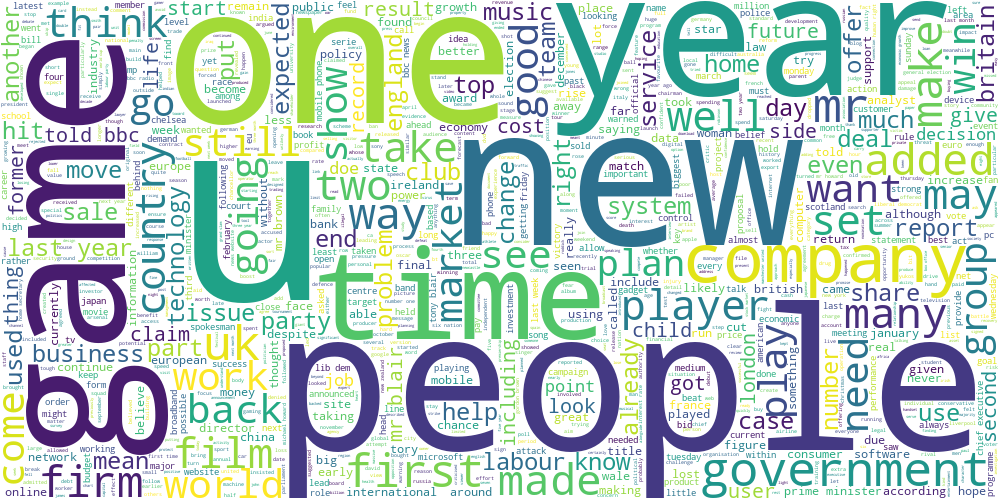

In [82]:
draw_wordcloud(data.text)

**Задание 2.1 (1 балл).** Обучите алгоритм K-Means на tf-idf представлениях текстов. При обучении tf-idf векторайзера рекомендуется отбрасывать редко встречающиеся слова, а также воздержитесь от использования N-грамм. Возьмите не очень большое число кластеров, чтобы было удобно интерпретировать получившиеся темы (например, `n_clusters` = 8). Постройте облака тегов для текстов из разных кластеров.

In [83]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(min_df=5)
vectors = vectorizer.fit_transform(data["text"])



In [84]:
model_kmeans_p2 = KMeans(random_state=42)

predicts_kmeans_p2 = model_kmeans_p2.fit_predict(vectors)

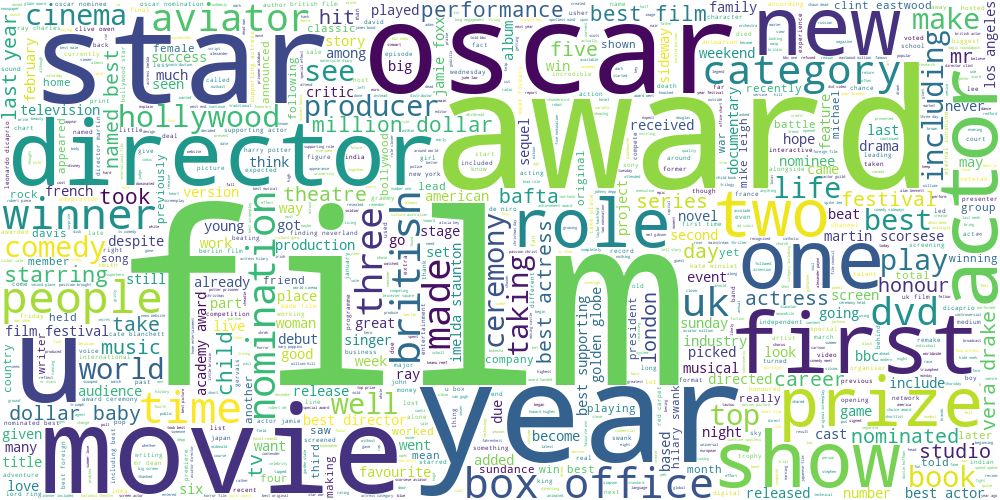

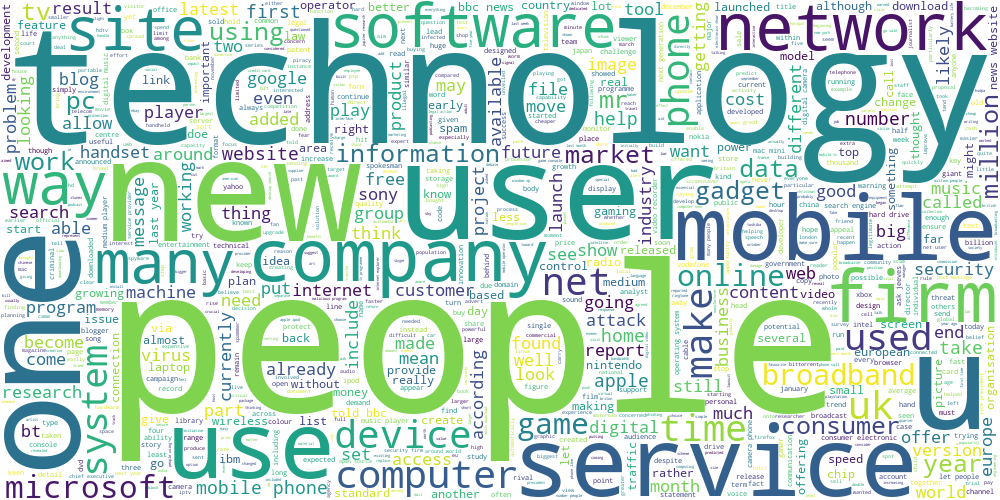

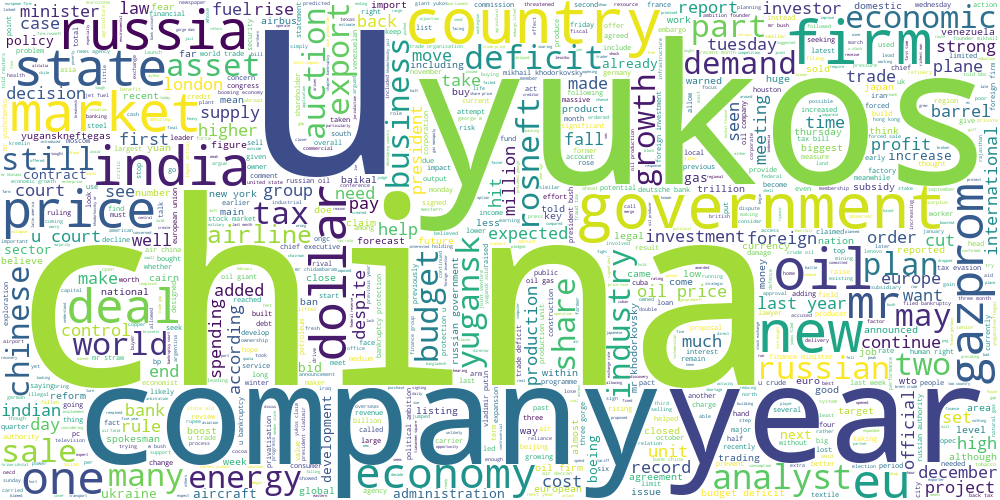

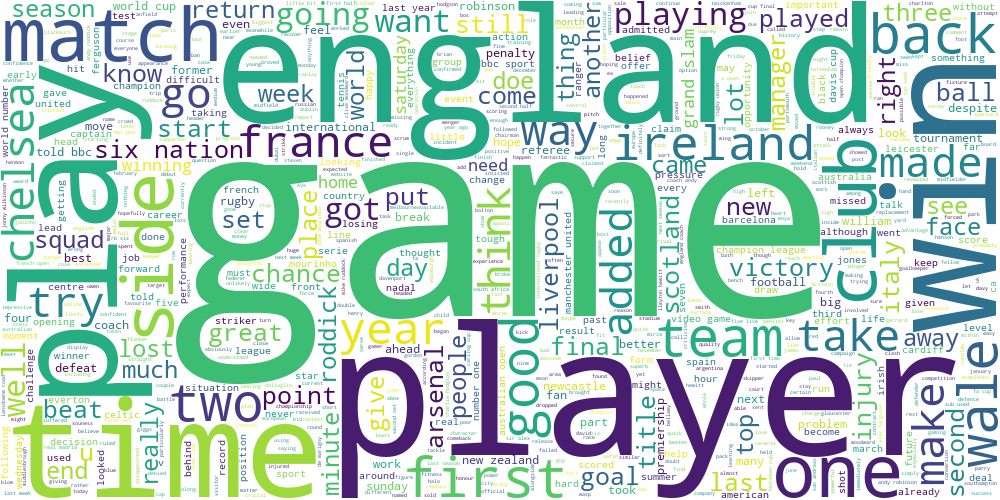

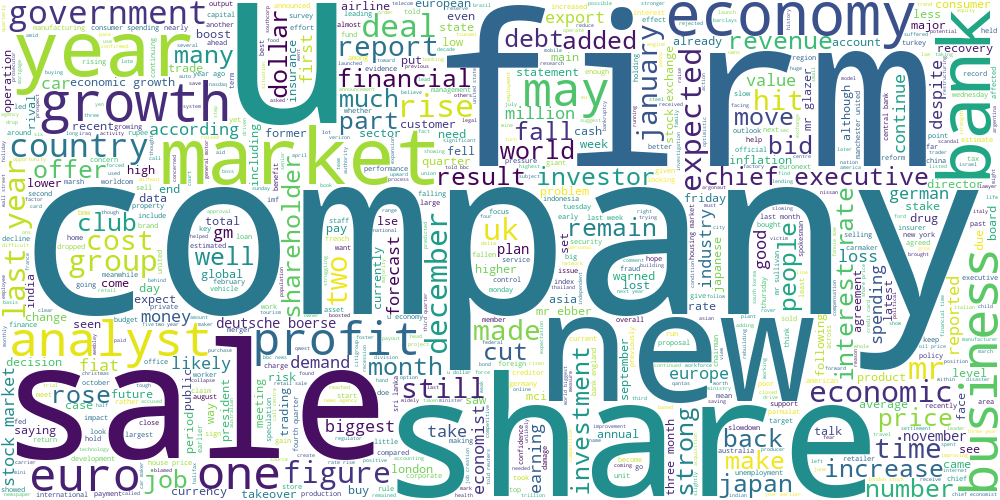

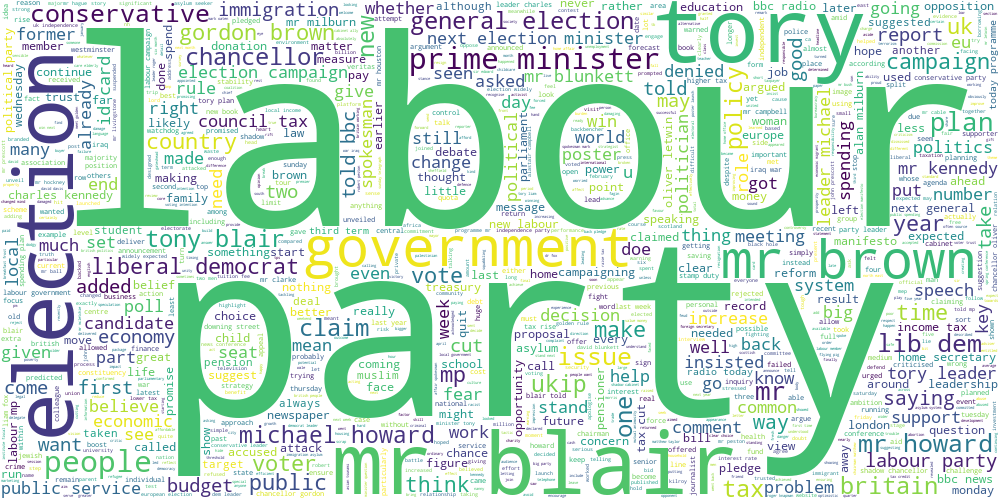

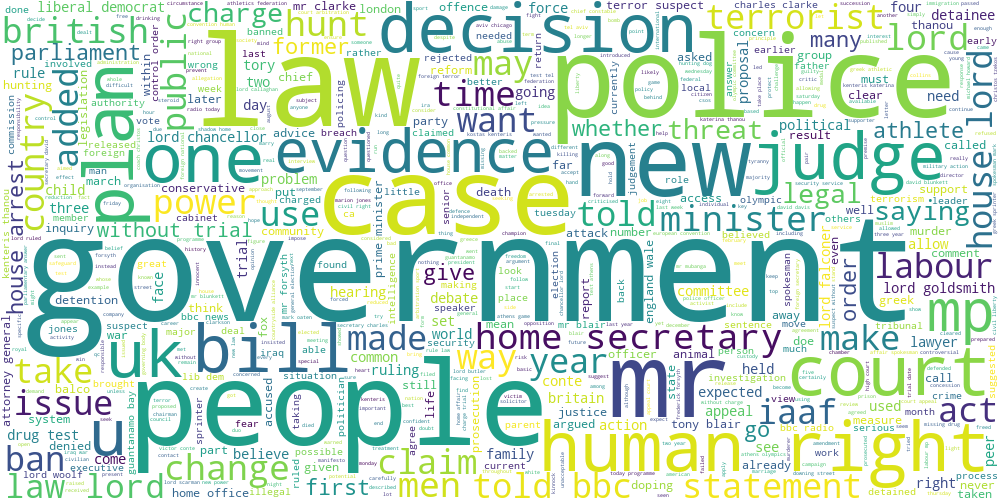

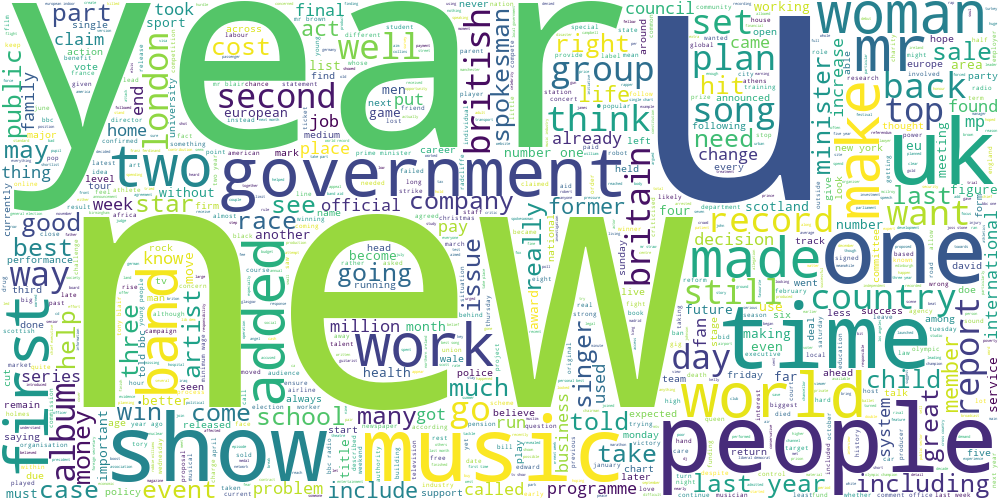

In [85]:
for cluster in np.unique(predicts_kmeans_p2):
    idxs = np.where(predicts_kmeans_p2 == cluster)[0]
    group = data.iloc[idxs]["text"]
    display(draw_wordcloud(group))

Получились ли темы интерпретируемыми? Попробуйте озаглавить каждую тему.

**Ответ:** Очень даже интерпретируемые. 
1. Кино и кинопремии.
2. Технологии и мобильная связь.
3. Нефть и мировая экономика.
4. Спорт, преимущественно футбол.
5. Бизнес и финансы.
6. Британская политика и выборы.
7. Право, суды и общественные вопросы.
8. Музыка и развлечения.

**Задание 2.2 (0.5 балла).** Попробуем другой способ выделить ключевые слова для каждой темы. Помимо непосредственного разбиения объектов алгоритм K-Means получает центр каждого кластера. Попробуйте взять центры кластеров и посмотреть на слова, для которых значения соответствующих им признаков максимальны.

In [86]:
words = vectorizer.get_feature_names_out()
centers = model_kmeans_p2.cluster_centers_

In [87]:
centers

array([[0.        , 0.        , 0.000983  , ..., 0.00039763, 0.        ,
        0.        ],
       [0.00015559, 0.        , 0.        , ..., 0.00065669, 0.00079638,
        0.00014393],
       [0.        , 0.        , 0.0008465 , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.00142214, ..., 0.00053757, 0.        ,
        0.        ],
       [0.        , 0.        , 0.00058856, ..., 0.        , 0.        ,
        0.        ],
       [0.00310782, 0.00015597, 0.00058802, ..., 0.00067623, 0.        ,
        0.00021992]], shape=(8, 7830))

In [88]:
for center in centers:
    top_words = np.argsort(center, descending=True)[:5]
    display(words[top_words])

array(['film', 'award', 'best', 'oscar', 'actor'], dtype=object)

array(['mobile', 'phone', 'technology', 'people', 'user'], dtype=object)

array(['oil', 'china', 'yukos', 'price', 'deficit'], dtype=object)

array(['game', 'england', 'player', 'match', 'win'], dtype=object)

array(['bank', 'share', 'growth', 'market', 'sale'], dtype=object)

array(['mr', 'labour', 'election', 'party', 'blair'], dtype=object)

array(['lord', 'law', 'police', 'court', 'government'], dtype=object)

array(['year', 'show', 'mr', 'music', 'band'], dtype=object)

Согласуются ли полученные слова с облаками тегов из прошлого задания?

**Ответ:** Ключевые слова согласуются с облаками: по ним узнаются кино, технологии, нефть, спорт, финансы, политика, право и музыка. Большинство тем хорошо интерпретируется, хотя некоторые объединяют несколько близких сюжетов

**Задание 2.3 (1.5 балла).** В первой части мы сравнили три разных алгоритма кластеризации на географических данных. Проделаем то же самое для текстовых данных (в качестве признакого описания снова используем tf-idf). Получите три разбиения на кластеры с помощью алгоритмов K-Means, DBSCAN и спектральной кластеризации (на этот раз воспользуйтесь реализацией из `sklearn`). Для K-Means и спектральной кластеризации возьмите одинаковое небольшое число кластеров, подберите параметр `eps` метода DBSCAN так, чтобы получить приблизительно такое же число кластеров (подумайте, как это можно сделать)

Далее, обучите двухмерные t-SNE представления над tf-idf признаками текстов. Визуализируйте эти представления для каждого алгоритма, раскрасив каждый кластер своим цветом. Лучше всего расположить визуализации на одном графике на трех разных сабплотах. Не забудьте, что DBSCAN помечает некоторые точки как шумовые (можно раскрасить их в отдельный цвет).

In [89]:
from sklearn.cluster import DBSCAN, SpectralClustering

model_dbscan_p2 = DBSCAN(eps=0.75, min_samples=10, metric="cosine")
model_spectral_p2 = SpectralClustering(random_state=42)


predicts_dbscan_p2 = model_dbscan_p2.fit_predict(vectors)
predicts_spectral_p2 = model_spectral_p2.fit_predict(vectors)


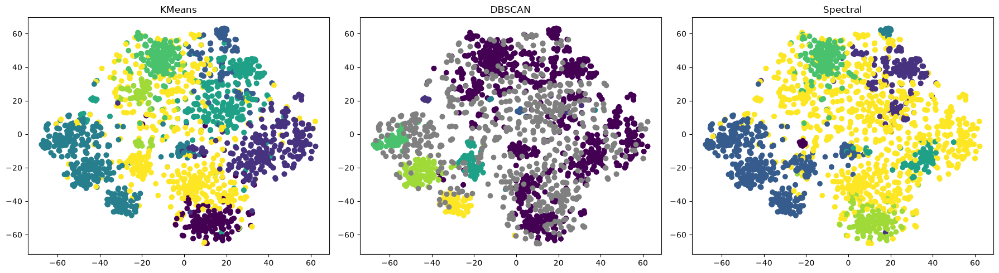

In [90]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

tsne = TSNE(random_state=42)

vectors_embedded = tsne.fit_transform(vectors)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(vectors_embedded[:, 0],
                vectors_embedded[:, 1],
                c=predicts_kmeans_p2)
axes[0].set_title("KMeans")

noise = predicts_dbscan_p2 == -1
axes[1].scatter(vectors_embedded[~noise, 0],
                vectors_embedded[~noise, 1],
                c=predicts_dbscan_p2[~noise])
axes[1].scatter(vectors_embedded[noise, 0],
                vectors_embedded[noise, 1],
                c="gray")
axes[1].set_title("DBSCAN")

axes[2].scatter(vectors_embedded[:, 0],
                vectors_embedded[:, 1],
                c=predicts_spectral_p2)
axes[2].set_title("Spectral")


plt.tight_layout()
plt.show()

Прокомментируйте получившиеся результаты. Какой баланс кластеров получился у разных методов? Соотносятся ли визуализации для текстов с визуализациями для географических данных?

**Ответ:** У KMeans группы получились более сбалансированными и визуально понятными. Спектральная кластеризация собрала много текстов в один большой кластер, а DBSCAN выделил несколько небольших групп, один большой кластер и около трети статей оставил шумом. Как и на географических данных, KMeans дал наиболее понятное разбиение, а у остальных методов группы получились менее равномерными

**Задание 2.4 (1.5 балла).** Обучите модель латентного размещения Дирихле. Не забудьте, что она работает с мешком слов, а не с tf-idf признаками. Придумайте, как превратить распределение тем для текста в номер его кластера. Возьмите параметр `n_components` в 2-3 раза больше, чем число кластеров для K-Means.

In [91]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(data["text"])

lda = LatentDirichletAllocation(n_components=20, random_state=42)
probs = lda.fit_transform(X)

clusters_lda = probs.argmax(axis=1)


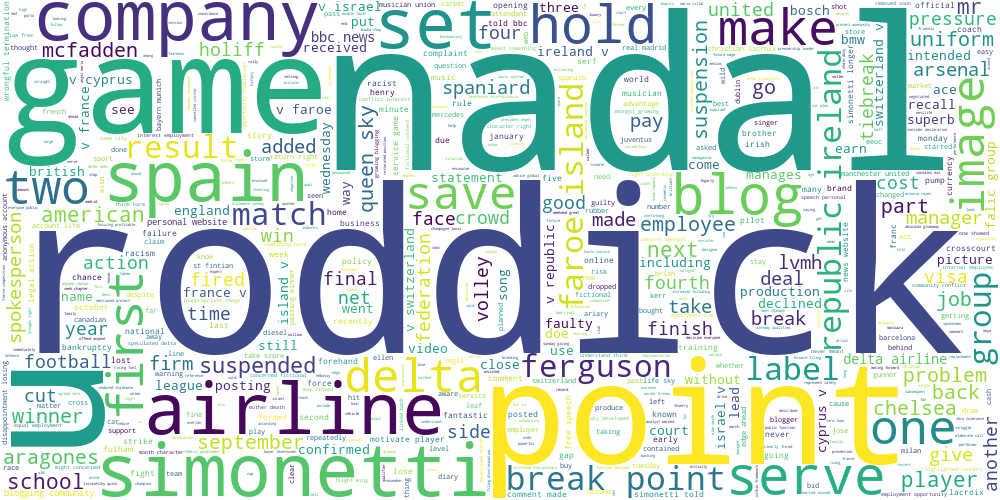

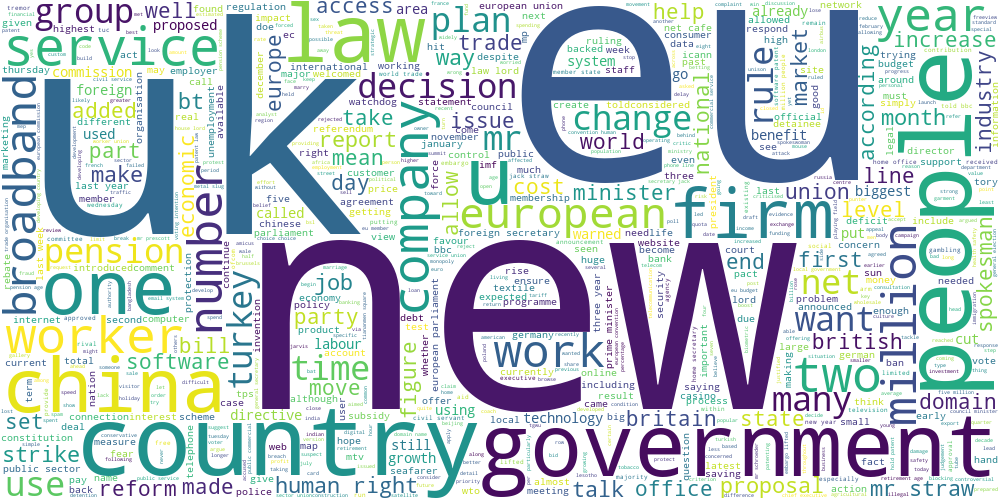

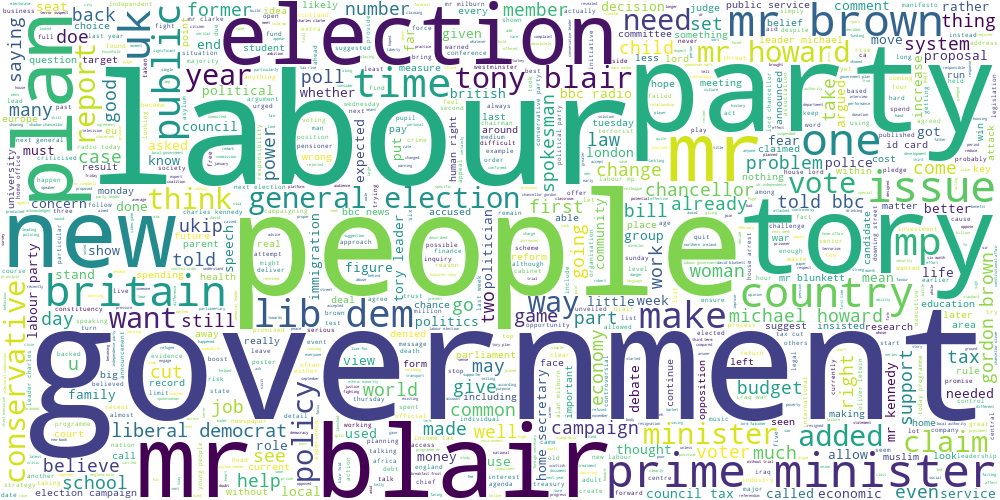

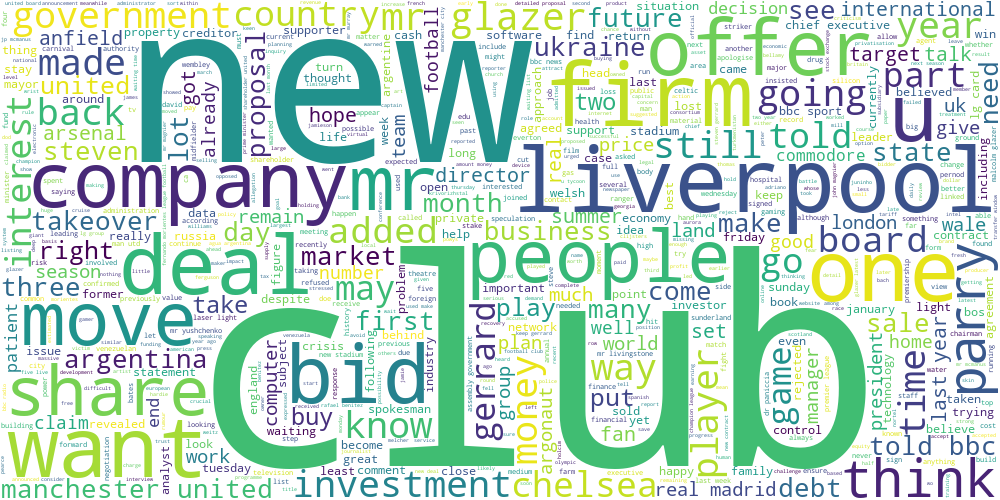

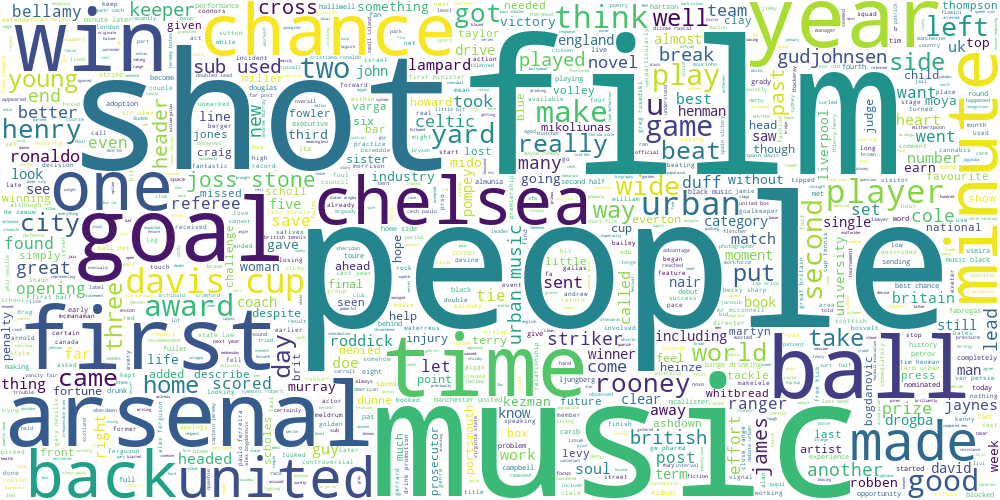

...

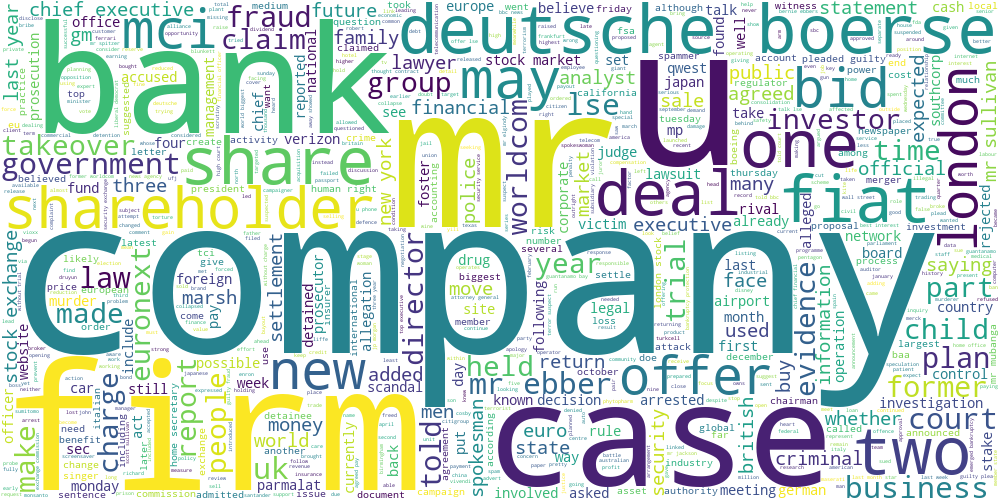

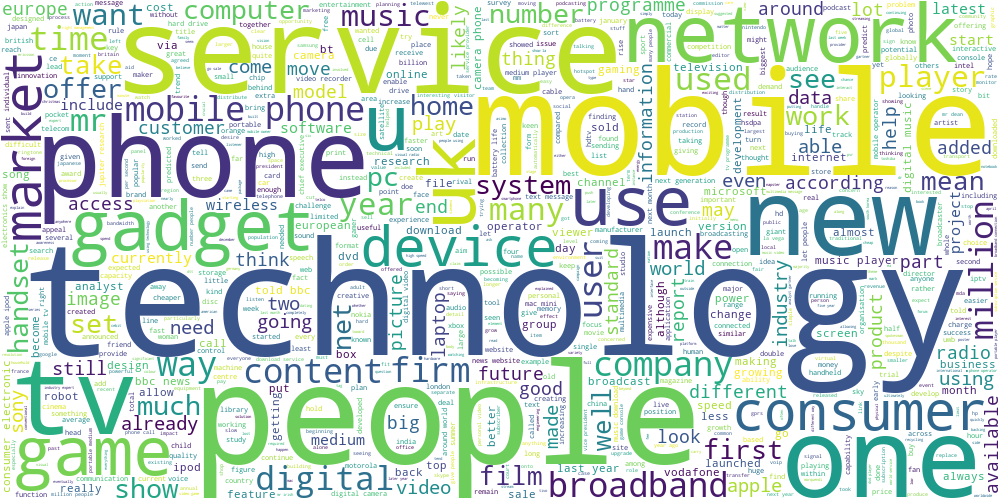

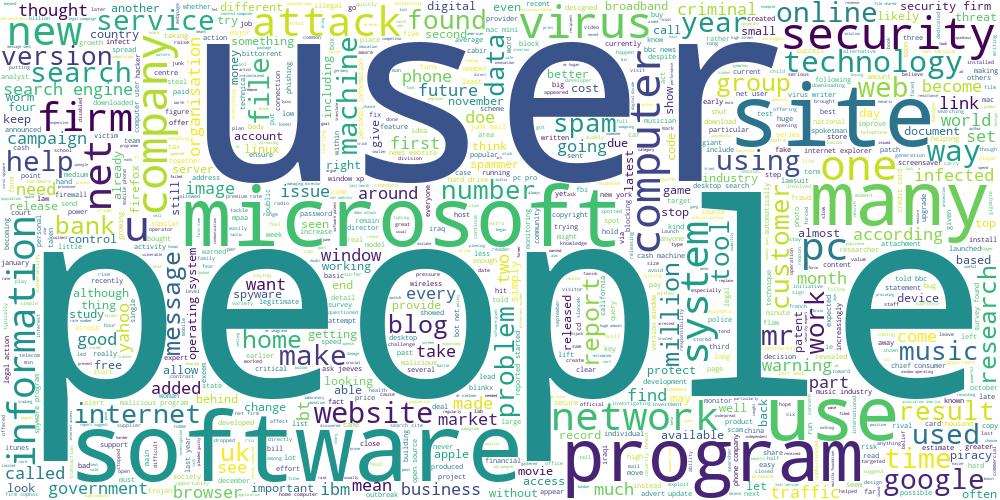

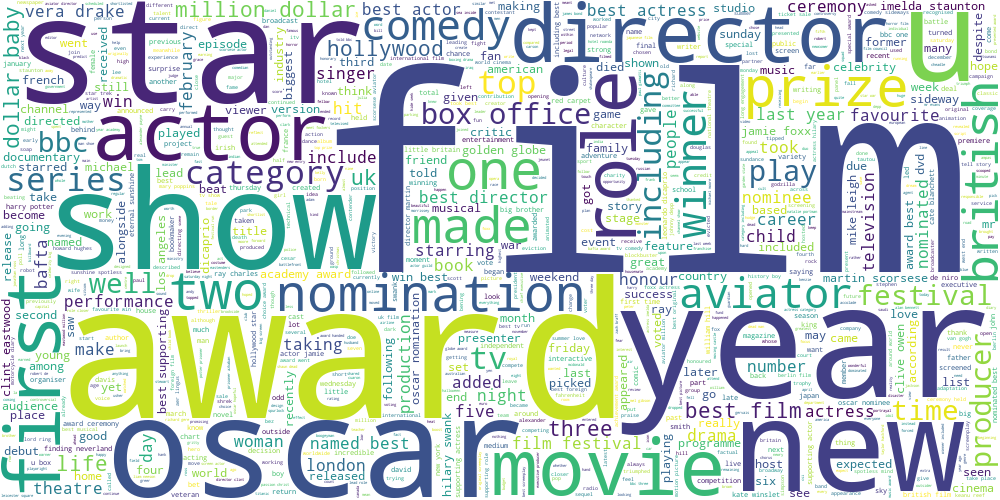

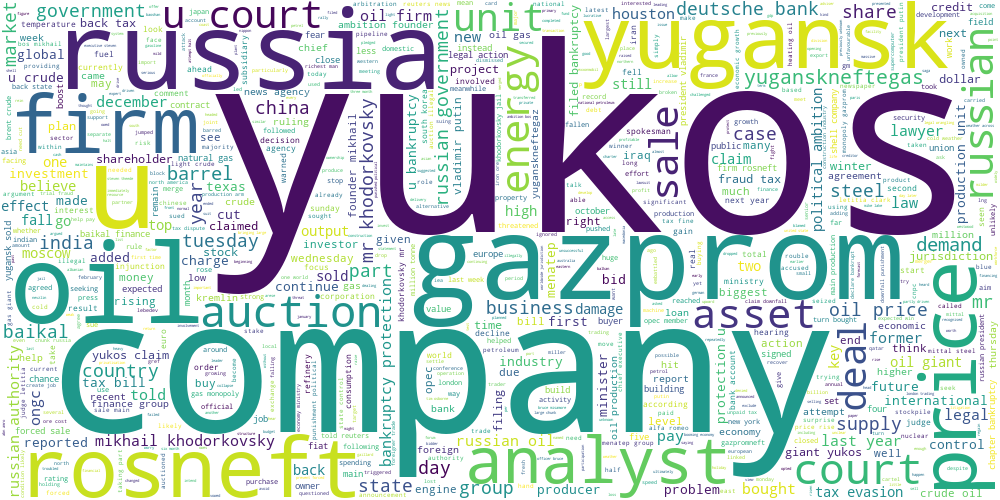

In [92]:
for cluster in np.unique(clusters_lda):
    idxs = np.where(clusters_lda == cluster)[0]
    group = data.iloc[idxs]["text"]
    display(draw_wordcloud(group))


Получились ли темы более узкими от такого нововведения? Постройте облака тегов для нескольких наиболее удачных тем.

**Ответ:** Некоторые темы стали более узкими: спортивная тематика разделилась на теннис, футбол и регби, а среди экономических статей выделилась группа про Газпром, ЮКОС и российский нефтегазовый сектор. Однако встречаются и смешанные группы, поэтому увеличение числа тем не гарантирует их осмысленность

## Часть 3. Transfer learning и Self-Supervised Learning для задачи классификации текстов

**Задание 3.1 (0.5 балла).** Вспомним, что у нас есть разметка для тематик статей. Попробуем обучить классификатор поверх unsupervised-представлений для текстов. Рассмотрите три модели:

* Логистическая регрессия на tf-idf признаках
* K-Means на tf-idf признаках + логистическая регрессия на расстояниях до центров кластеров
* Латентное размещение Дирихле + логистическая регрессия на вероятностях тем

Разделите выборку на обучающую и тестовую, замерьте accuracy на обоих выборках для всех трех моделей. Параметры всех моделей возьмите равными значениям по умолчанию.

In [111]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(np.arange(data.shape[0]), random_state=42, stratify=data["category"])
train_tf_idf = TfidfVectorizer()
X_tf_idf_train = train_tf_idf.fit_transform(data.iloc[train_idx]["text"]).tocsr()
X_tf_idf_test = train_tf_idf.transform(data.iloc[test_idx]["text"]).tocsr()

kmeans_p3 = KMeans(random_state=42)
kmeans_p3.fit(X_tf_idf_train)
X_kmeans = kmeans_p3.transform(X_tf_idf_train)

vectorizer_p3 = CountVectorizer()
X_counts_train = vectorizer_p3.fit_transform(data.iloc[train_idx]["text"])
X_counts_test = vectorizer_p3.transform(data.iloc[test_idx]["text"])
lda_p3 = LatentDirichletAllocation(random_state=42)
X_lda = lda_p3.fit_transform(X_counts_train)

y = data["category"]

In [112]:
model_1 = LogisticRegression()
model_2 = LogisticRegression()
model_3 = LogisticRegression()

model_1.fit(X_tf_idf_train, y[train_idx])
model_2.fit(X_kmeans, y[train_idx])
model_3.fit(X_lda, y[train_idx])

train_predict_1 = model_1.predict(X_tf_idf_train)
train_predict_2 = model_2.predict(X_kmeans)
train_predict_3 = model_3.predict(X_lda)
test_predict_1 = model_1.predict(X_tf_idf_test)
test_predict_2 = model_2.predict(kmeans_p3.transform(X_tf_idf_test))
test_predict_3 = model_3.predict(lda_p3.transform(X_counts_test))

In [113]:
print(
    accuracy_score(y[train_idx], train_predict_1),
    accuracy_score(y[test_idx], test_predict_1),
)


0.9970023980815348 0.9784560143626571


In [114]:
print(
    accuracy_score(y[train_idx], train_predict_2),
    accuracy_score(y[test_idx], test_predict_2),
)


0.8063549160671463 0.8168761220825853


In [115]:
print(
    accuracy_score(y[train_idx], train_predict_3),
    accuracy_score(y[test_idx], test_predict_3),
)


0.88189448441247 0.9245960502692998


У какой модели получилось лучшее качество? С чем это связано?

**Ответ:** Лучше всего отработала логистическая регрессия на чистом TF-IDF. Там много признаков и размерность грубо говоря не сжата, информации много и она подходит для линейной модели. KMeans и LDA информацию значительно сжимают и могут терять важные для классификации различия

**Задание 3.2 (1.5 балла).** Теперь просимулируем ситуацию слабой разметки, которая часто встречается в реальных данных. Разделим обучающую выборку в пропорции 5:65:30. Будем называть части, соответственно, размеченный трейн, неразмеченный трейн и валидация.

Все unsupervised-алгоритмы (векторайзеры и алгоритмы кластеризации) запускайте на всем трейне целиком (размеченном и неразмеченном, суммарно 70%), а итоговый классификатор обучайте только на размеченном трейне (5%). Подберите гиперпараметры моделей по качеству на валидации (30%), а затем оцените качество на тестовой выборке (которая осталась от прошлого задания). Не скромничайте при подборе числа кластеров, сейчас нас интересует не интерпретируемое разбиение выборки, а итоговое качество классификации.

In [116]:
train, val_idx = train_test_split(train_idx, test_size=0.3, random_state=42, stratify=y.iloc[train_idx])
marked_train_idx, unmarked_train_idx = train_test_split(train, test_size=65/70, random_state=42, stratify=y.iloc[train])

best_min_df = 0
best_acc = 0
for min_df in [1, 2, 5]:
    train_tf_idf_32 = TfidfVectorizer(min_df=min_df)
    X_tf_idf_32 = train_tf_idf_32.fit_transform(data.iloc[train]["text"]).tocsr()
    X_tf_idf_train_32 = train_tf_idf_32.transform(data.iloc[marked_train_idx]["text"]).tocsr()
    X_tf_idf_test_32 = train_tf_idf_32.transform(data.iloc[test_idx]["text"]).tocsr()
    X_tf_idf_val_32 = train_tf_idf_32.transform(data.iloc[val_idx]["text"]).tocsr()
    
    model_4 = LogisticRegression()
    model_4.fit(X_tf_idf_train_32, y[marked_train_idx])
    val_predict_4 = model_4.predict(X_tf_idf_val_32)
    metric = accuracy_score(y[val_idx], val_predict_4)
    
    print(metric, min_df)
    
    if metric >  best_acc:
        best_min_df = min_df
        best_acc = metric

train_tf_idf_32 = TfidfVectorizer(min_df=best_min_df)
X_tf_idf_32 = train_tf_idf_32.fit_transform(data.iloc[train]["text"]).tocsr()
X_tf_idf_train_32 = train_tf_idf_32.transform(data.iloc[marked_train_idx]["text"]).tocsr()
X_tf_idf_test_32 = train_tf_idf_32.transform(data.iloc[test_idx]["text"]).tocsr()
X_tf_idf_val_32 = train_tf_idf_32.transform(data.iloc[val_idx]["text"]).tocsr()

model_4 = LogisticRegression()
model_4.fit(X_tf_idf_train_32, y[marked_train_idx])
test_predict_4 = model_4.predict(X_tf_idf_test_32)

print(accuracy_score(y[test_idx], test_predict_4), best_min_df)


0.8023952095808383 1
0.810379241516966 2
0.8502994011976048 5
0.8707360861759426 5


In [117]:
best_k = 0
best_acc = 0
for k in [8, 30, 60, 100, 200, 300]:
    kmeans_32 = KMeans(random_state=42, n_clusters=k, n_init=10)
    kmeans_32.fit(X_tf_idf_32)
    X_kmeans_32 = kmeans_32.transform(X_tf_idf_train_32)
    
    model_5 = LogisticRegression(max_iter=1000)
    model_5.fit(X_kmeans_32, y[marked_train_idx])
    val_predict_5 = model_5.predict(kmeans_32.transform(X_tf_idf_val_32))
    
    metric = accuracy_score(y[val_idx], val_predict_5)
    
    print(metric, k)
    
    if metric > best_acc:
        best_acc = metric
        best_k = k

kmeans_32 = KMeans(random_state=42, n_clusters=best_k, n_init=10)
kmeans_32.fit(X_tf_idf_32)
X_kmeans_32 = kmeans_32.transform(X_tf_idf_train_32)

model_5 = LogisticRegression(max_iter=1000)
model_5.fit(X_kmeans_32, y[marked_train_idx])
test_predict_5 = model_5.predict(kmeans_32.transform(X_tf_idf_test_32))

print(accuracy_score(y[test_idx], test_predict_5), best_k)

0.46107784431137727 8
0.5848303393213573 30
0.7225548902195609 60
0.8043912175648703 100
0.8882235528942116 200
0.9021956087824351 300
0.9156193895870736 300


In [118]:
best_n = 0
best_acc = 0
for n in [10, 20, 40, 80]:
    vectorizer_32 = CountVectorizer(min_df=2, max_df=0.95)
    X_counts_32 = vectorizer_32.fit_transform(data.iloc[train]["text"])
    X_counts_train_32 = vectorizer_32.transform(data.iloc[marked_train_idx]["text"])
    X_counts_test_32 = vectorizer_32.transform(data.iloc[test_idx]["text"])
    X_counts_val_32 = vectorizer_32.transform(data.iloc[val_idx]["text"])
    lda_32 = LatentDirichletAllocation(random_state=42, n_components=n, max_iter=20)
    X_lda_32 = lda_32.fit(X_counts_32)
    X_lda_train_32 = lda_32.transform(X_counts_train_32)
    
    model_6 = LogisticRegression()
    model_6.fit(X_lda_train_32, y[marked_train_idx])
    val_predict_6 = model_6.predict(lda_32.transform(X_counts_val_32))
    metric = accuracy_score(y[val_idx], val_predict_6)
    
    print(metric, n)
    
    if metric > best_acc:
        best_acc = metric
        best_n = n

vectorizer_32 = CountVectorizer(min_df=2, max_df=0.95)
X_counts_32 = vectorizer_32.fit_transform(data.iloc[train]["text"])
X_counts_train_32 = vectorizer_32.transform(data.iloc[marked_train_idx]["text"])
X_counts_test_32 = vectorizer_32.transform(data.iloc[test_idx]["text"])
lda_32 = LatentDirichletAllocation(random_state=42, n_components=best_n, max_iter=20)
X_lda_32 = lda_32.fit(X_counts_32)
X_lda_train_32 = lda_32.transform(X_counts_train_32)

model_6 = LogisticRegression()
model_6.fit(X_lda_train_32, y[marked_train_idx])
test_predict_6 = model_6.predict(lda_32.transform(X_counts_test_32))
print(accuracy_score(y[test_idx], test_predict_6), best_n)

0.9101796407185628 10
0.9281437125748503 20
0.8882235528942116 40
0.8403193612774451 80
0.940754039497307 20


Как изменились результаты по сравнению с обучением на полной разметке? Сделайте выводы.

**Ответ:** При использовании только 5% размеченных статей accuracy TF-IDF снизилась с 97,85% до 87%. K-Means с 300 кластерами достиг 91,5%, а LDA с 20 темами — 94%, показав лучший результат. Представления через кластеры и темы оказались полезны при малой разметке, но улучшение относительно 3.1 связано также с подбором гиперпараметров.

## Бонус

**Задание 4 (0.5 балла)**. Разберитесь с semi-supervised методами, которые реализованы в `sklearn` и примените их к заданию 3.2. Получилось ли добиться лучшего качества? Сделайте выводы.

In [119]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

**Задание 5 (0.5 балла)**. На занятиях мы обсуждали, что метрика [BCubed](https://www.researchgate.net/profile/Julio-Gonzalo-2/publication/225548032_Amigo_E_Gonzalo_J_Artiles_J_et_alA_comparison_of_extrinsic_clustering_evaluation_metrics_based_on_formal_constraints_Inform_Retriev_12461-486/links/0c96052138dbb99740000000/Amigo-E-Gonzalo-J-Artiles-J-et-alA-comparison-of-extrinsic-clustering-evaluation-metrics-based-on-formal-constraints-Inform-Retriev-12461-486.pdf) хорошо подходит для сравнения алгоритмов кластеризации, если нам известно настоящее разделение на кластеры (gold standard). Реализуйте подсчет метрики BCubed и сравните несколько алгоритмов кластеризации на текстовых данных из основного задания. В качестве gold standard используйте разметку category.

In [120]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

**Задание 6 (1 балл)**. Спектральная кластеризация, по сути, является обычной кластеризацией KMeans поверх эмбеддингов объектов, которые получаются из лапласиана графа. А что, если мы попробуем построить эмбеддинги каким-нибудь другим способом? В этом задании мы предлагаем вам проявить немного фантазии. Возьмите какие-нибудь данные высокой размерности, чтобы задача обучения эмбеддингов имела смысл (например, картинки или тексты, желательно выбрать что-нибудь оригинальное). Придумайте или найдите какой-нибудь метод обучения эмбеддингов, примените его к данным и кластеризуйте полученные представления. Если чувствуете в себе достаточно силы, можете попробовать что-нибудь нейросетевое. Сравните ваш подход с базовыми алгоритмами кластеризации, которое мы рассмотрели в основном задании, не забывайте про визуализации! Ключевые слова для вдохновения: ***KernelPCA***, ***UMAP***, ***autoencoders***, ***gensim***.

In [121]:
# YOUR CODE HERE ‿︵‿︵ヽ(°□° )ノ︵‿︵‿

**Задание 7 (0.5 балла)**. Наконец, ставший ежегодной традицией социализационный бонус. Мы поощряем не только предметное, но и духовное развитие. Поэтому, чтобы заработать полбалла за это задание, сходите на какую-нибудь выставку, в музей, театр, или наконец в церковь, напишите небольшой отчетик о ваших впечатлениях и добавьте фотопруфы в ноутбук при сдаче. Можете объединиться с одногруппниками/однокурсниками, а также пригласить ассистентов/преподавателей, они тоже будут рады выбраться куда-нибудь. Для вдохновения приведем ссылку на актуальные выставки [новой](https://www.youtube.com/watch?v=dQw4w9WgXcQ&ab) и [старой Третьяковки](https://www.youtube.com/watch?v=X1-MXdyThJ0) (но совсем не обязательно посещать именно их).

Был в церкви, но не сфотографировал тк было запрещено. Впечатления следующие - церковь непримечательная и небольшая. Внутри практически никого не было, так что получилось в одиночестве посидеть и подумать о насущных, скажем так, проблемах. А был я в Храме Живоначальной Троицы в Хохлах, 55.756699, 37.643892